# Issue #284 — joint parameter interaction screen

This notebook screens `N × K × generator × subset family` while keeping one
Beijing issue as the independent historical unit. Weighted-ticket stream seeds
and sampled subsets are nuisance replicas: they are averaged and are never
eligible optimization parameters. All results are pre-tax and no 2024+ outcome
is opened.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
RESULTS = ROOT / 'results/issue-284'
raw = pd.read_parquet(RESULTS / 'joint_action_grid_confirmatory.parquet')
curve = pd.read_csv(RESULTS / 'joint_action_curve.csv')
yearly = pd.read_csv(RESULTS / 'joint_action_yearly.csv')
family = pd.read_csv(RESULTS / 'joint_family_curve.csv')
lift = pd.read_csv(RESULTS / 'joint_generator_lift.csv')
policy_metrics = pd.read_csv(RESULTS / 'joint_policy_oof_metrics.csv')
policy_selected = pd.read_parquet(RESULTS / 'joint_policy_oof_selected.parquet')
policy_diagnostics = pd.read_csv(RESULTS / 'joint_policy_oof_diagnostics.csv')
policy_actions = pd.read_csv(RESULTS / 'joint_policy_oof_action_counts.csv')
outcome_actions = pd.read_csv(RESULTS / 'outcome_surface_action_summary.csv')
outcome_annual = pd.read_csv(RESULTS / 'outcome_surface_annual.csv')
outcome_focus = pd.read_csv(RESULTS / 'outcome_surface_n7_top_k8.csv')
outcome_receipt = json.loads((RESULTS / 'outcome_surface_reuse_receipt.json').read_text())
outcome_joint = pd.read_csv(RESULTS / 'outcome_joint_issue_actions.csv')
div_n8 = pd.read_csv(RESULTS / 'divergence_n8_shape_k16_action_summary.csv')
div_n9 = pd.read_csv(RESULTS / 'divergence_n9_div_k64_action_summary.csv')
mode_metrics = pd.read_csv(RESULTS / 'divergence_mode_oof_metrics.csv')
mode_selected = pd.read_csv(RESULTS / 'divergence_mode_oof_selected.csv')
receipt = json.loads((RESULTS / 'joint_action_analysis_receipt.json').read_text())
assert raw.issue_year.max() <= 2023
{
    'issues': raw.issue.nunique(),
    'rows': len(raw),
    'subsets': raw.subset_id.nunique(),
    'N': sorted(raw.n.unique().tolist()),
    'weighted_stream_replicas': receipt['weighted_stream_replicas'],
    'sealed_years_opened': receipt['sealed_years_opened'],
}

{'issues': 620,
 'rows': 1106532,
 'subsets': 39519,
 'N': [7, 8, 9, 10],
 'weighted_stream_replicas': 3,
 'sealed_years_opened': []}

## Why the hierarchy matters

The optimization vector is `(N, K, generator, subset/selector, later R and W)`.
The stream seed is only Monte Carlo integration, and multiple subsets are
nested observations inside an issue. Selecting the luckiest seed or subset
would leak realized lottery variance into the policy.

In [2]:
curve.sort_values(
    ['ex_largest_roi_pct', 'mean_roi_pct'], ascending=False
).head(20)[[
    'n','generator','requested_k','mean_roi_pct','ex_largest_roi_pct',
    'bootstrap_low_pct','bootstrap_high_pct','positive_years',
    'median_issue_roi_pct','longest_losing_issue_streak'
]]

,n,generator,requested_k,mean_roi_pct,ex_largest_roi_pct,bootstrap_low_pct,bootstrap_high_pct,positive_years,median_issue_roi_pct,longest_losing_issue_streak
2,10,WEIGHTED_WR,128,5.433441,0.703439,-20.184787,36.571539,3,-100.000000,27
3,9,TOP_VALUE,8,4.660138,-1.928946,-30.086807,43.355386,7,-100.000000,52
4,10,TOP_VALUE,256,-1.758128,-3.219391,-14.061018,10.844500,4,-100.000000,11
5,7,TOP_VALUE,8,-2.025189,-3.848764,-17.034023,14.454001,5,-100.000000,22
1,9,WEIGHTED_WR,16,6.937232,-4.640113,-30.837591,53.839821,6,-100.000000,35
0,9,WEIGHTED_WR,8,13.913972,-6.982725,-39.810519,81.477600,6,-100.000000,85
10,10,TOP_VALUE,512,-6.146792,-7.154472,-15.316695,3.745238,2,-44.526556,13
12,9,TOP_VALUE,256,-6.996645,-8.369623,-15.905985,2.678512,4,-47.071724,13
14,7,TOP_VALUE,16,-7.584833,-9.062011,-18.676000,3.511185,4,-100.000000,14
8,10,WEIGHTED_WR,256,-5.407498,-9.450120,-23.105842,13.520009,5,-100.000000,16


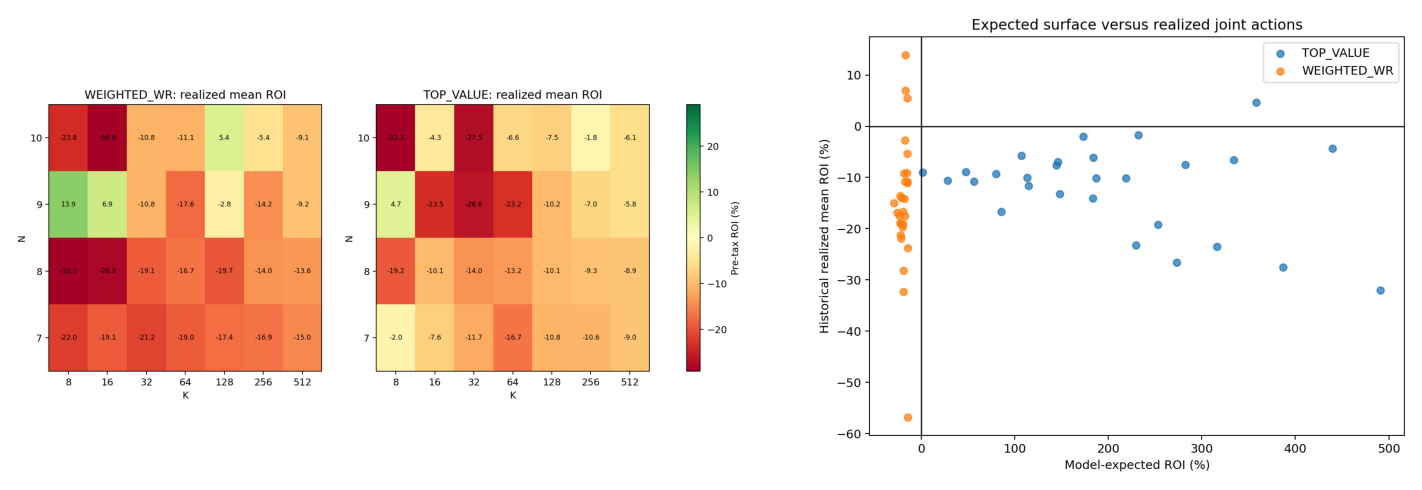

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].imshow(plt.imread(RESULTS / 'joint_action_roi_heatmaps.png'))
axes[0].axis('off')
axes[1].imshow(plt.imread(RESULTS / 'joint_expected_vs_realized.png'))
axes[1].axis('off')
plt.tight_layout()

## Is generator choice stable after matching N and K?

In [4]:
lift.sort_values('mean_lift_pct', ascending=False).head(24)

,n,requested_k,mean_lift_pct,median_lift_pct,positive_lift_fraction
0,9,16,30.428410,0.000000,0.069467
1,10,32,16.747814,0.000000,0.045234
2,9,32,15.746355,0.000000,0.113086
3,10,128,12.979342,0.000000,0.151858
4,9,8,9.253834,0.000000,0.042003
5,10,8,8.233636,0.000000,0.011309
6,9,128,7.402351,0.000000,0.315024
7,9,64,5.653030,0.000000,0.203554
8,7,64,-2.299186,-0.358370,0.448387
9,10,512,-2.978360,0.000000,0.321486


## Does the apparent action persist across years?

In [5]:
candidate = curve.sort_values('ex_largest_roi_pct', ascending=False).head(8)
keys = candidate[['n','generator','requested_k']]
candidate_years = yearly.merge(keys, on=['n','generator','requested_k'])
candidate_years.pivot_table(
    index=['n','generator','requested_k'],
    columns='issue_year', values='realized_roi_pct'
).round(2)

issue_year                   2014   2015   2016    2017   2018   2019   2020  \
n  generator   requested_k                                                     
7  TOP_VALUE   8           -10.49  15.06 -24.78   40.60   4.37   7.53 -44.66   
9  TOP_VALUE   8            15.30  30.77 -22.64   51.59  15.94  11.00  86.26   
               256         -24.24   8.28 -24.57   12.14  -7.62  18.42  -9.99   
   WEIGHTED_WR 8             0.69  -0.69  18.59 -100.00  22.16 -76.66  31.34   
               16           33.05   9.71  19.79  -42.77   0.89 -63.21 -34.33   
10 TOP_VALUE   256           6.68 -13.50  -3.19   21.11   2.18  -1.66 -26.80   
               512          -6.74  -5.06  -2.65    7.78 -28.77  -0.47  -6.04   
   WEIGHTED_WR 128          -6.07  75.71  60.78  -36.59 -12.85 -33.18  96.11   

issue_year                   2021   2022    2023  
n  generator   requested_k                        
7  TOP_VALUE   8            -5.37 -15.92   20.23  
9  TOP_VALUE   8            31.01 -87.30  -64.53  
               256           9.57 -21.94   -3.20  
   WEIGHTED_WR 8            -1.32  88.65  161.40  
               16          -42.95   3.53  138.21  
10 TOP_VALUE   256         -39.27  27.52   -7.17  
               512         -10.63   0.65   -5.05  
   WEIGHTED_WR 128         -32.17  -0.46   -8.01

## Expanding-window Data-conditioned joint policy

In [6]:
policy_metrics[[
    'policy','mean_roi_pct','mean_matched_lift_pct',
    'bootstrap_lift_low_pct','bootstrap_lift_high_pct',
    'positive_lift_years','ending_capital_cny','max_drawdown_fraction',
    'longest_losing_issue_streak','fallback_fraction','selected_action_entropy'
]]

,policy,mean_roi_pct,mean_matched_lift_pct,bootstrap_lift_low_pct,bootstrap_lift_high_pct,positive_lift_years,ending_capital_cny,max_drawdown_fraction,longest_losing_issue_streak,fallback_fraction,selected_action_entropy
0,FIXED_N7_TOP_K8,-3.943010,14.627985,-8.495525,38.147557,4,98706.692709,0.037069,22,0.0,-0.000000
1,HIST_FULL_FORCED,-9.237502,9.333493,0.073195,19.326774,5,96970.099267,0.034556,11,0.0,0.326421
2,HIST_ACTION_FORCED,-10.584945,7.986050,-0.659253,16.339238,5,96528.138025,0.035418,11,0.0,0.567668
3,HIST_STATE_FORCED,-10.727623,7.843372,-0.806110,16.347762,5,96481.339731,0.036078,11,0.0,0.319691
4,MLP_FORCED,-10.953367,7.617628,-0.886301,16.858852,5,96407.295490,0.036626,11,0.0,0.093387
5,FIXED_N7_TOP_K512,-11.039818,7.531177,-1.335662,16.161120,5,96378.939777,0.036910,11,0.0,-0.000000
6,RIDGE_FORCED,-11.985263,6.585732,-1.756973,14.965435,5,96068.833802,0.040009,13,0.0,0.229197
7,ACTION_MEDIAN_FORCED,-17.197958,1.373037,-8.452258,9.751040,5,94359.069617,0.056759,9,0.0,1.179763
8,FIXED_BASELINE,-18.570995,0.000000,0.000000,0.000000,0,93908.713597,0.060913,15,0.0,-0.000000
9,HIST_ACTION_Q10_FALLBACK,-18.570995,0.000000,0.000000,0.000000,0,93908.713597,0.060913,15,1.0,-0.000000


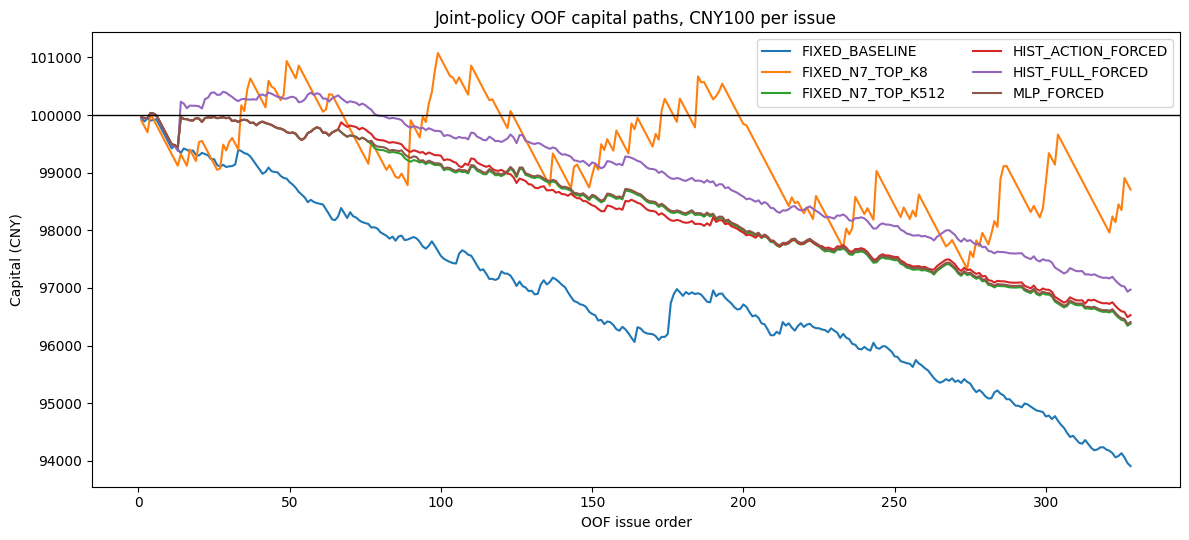

In [7]:
fig, ax = plt.subplots(figsize=(12, 5.5))
show = [
    'FIXED_BASELINE','FIXED_N7_TOP_K8','FIXED_N7_TOP_K512',
    'HIST_ACTION_FORCED','HIST_FULL_FORCED','MLP_FORCED'
]
for policy in show:
    group = policy_selected.loc[policy_selected.policy.eq(policy)].sort_values(['issue_year','issue'])
    capital = 100_000 + group.realized_roi_pct.cumsum()
    ax.plot(range(1, len(group)+1), capital, label=policy)
ax.axhline(100_000, color='black', linewidth=1)
ax.set(xlabel='OOF issue order', ylabel='Capital (CNY)', title='Joint-policy OOF capital paths, CNY100 per issue')
ax.legend(ncol=2); plt.tight_layout()

In [8]:
policy_actions.loc[
    policy_actions.policy.isin(['HIST_ACTION_FORCED','HIST_FULL_FORCED','MLP_FORCED'])
].groupby('policy').head(10)

,policy,action_key,issues,realized_roi_pct
15,HIST_ACTION_FORCED,N7_TOP_VALUE_K512_FENSEMBLE,275,-10.840378
16,HIST_ACTION_FORCED,N7_WEIGHTED_WR_K512_FENSEMBLE,38,-14.552227
17,HIST_ACTION_FORCED,N7_TOP_VALUE_K256_FENSEMBLE,10,-13.371709
18,HIST_ACTION_FORCED,N8_TOP_VALUE_K512_FENSEMBLE,5,39.188740
20,HIST_FULL_FORCED,N7_TOP_VALUE_K512_FENSEMBLE,295,-12.149384
21,HIST_FULL_FORCED,N7_TOP_VALUE_K256_FENSEMBLE,33,16.792954
26,MLP_FORCED,N7_TOP_VALUE_K512_FENSEMBLE,323,-10.939272
27,MLP_FORCED,N7_WEIGHTED_WR_K512_FENSEMBLE,3,-3.482008
28,MLP_FORCED,N7_TOP_VALUE_K512_FDIVERGENCE_WEIGHTED,1,14.245594
29,MLP_FORCED,N8_TOP_VALUE_K512_FENSEMBLE,1,-63.119094


In [9]:
policy_diagnostics

,model,overall_spearman,within_action_spearman_mean,within_issue_spearman_mean,q10_empirical_below_fraction
0,EXPECTED_ONLY,-0.094732,0.009257,-0.175829,0.117959
1,ACTION_MEDIAN,0.323163,-0.054603,0.546678,0.117959
2,RIDGE,0.332972,0.097336,0.543674,0.117959
3,HIST_ACTION,0.334342,0.083291,0.532862,0.117959
4,HIST_STATE,0.241285,0.019903,0.524271,0.117959
5,HIST_FULL,0.240902,0.015137,0.527275,0.117959
6,MLP,0.329168,0.090735,0.535198,0.117959


MLP still collapses onto the static
`N7/TOP_VALUE/K512/ENSEMBLE` action, differing in only 5/328 issues and adding
about +0.086pp with no separated confidence interval. Full-HGB is more
interesting: it chooses K256 in 33 issues and K512 in 295, adding +1.80pp over
fixed K512 (+0.80pp ex-largest), but its paired bootstrap interval still
crosses zero. This is a conditional-K sweet-zone clue rather than a reliable
learned policy. `EXPECTED_ONLY` is strongly harmful, while the q10 safety head
falls back in every issue.

## Does one outcome-value surface win across regimes?

In [10]:
outcome_focus[[
    'outcome_weight_mode','development_roi_pct','holdout_roi_pct',
    'mean_roi_pct','ex_largest_roi_pct','bootstrap_low_pct',
    'bootstrap_high_pct','positive_years'
]]

,outcome_weight_mode,development_roi_pct,holdout_roi_pct,mean_roi_pct,ex_largest_roi_pct,bootstrap_low_pct,bootstrap_high_pct,positive_years
0,MARKET_PROBABILITY,38.540524,-33.055791,32.420194,14.716641,-18.793671,95.850039,3
1,CELL_VALUE,-42.373748,-100.000000,-47.299863,-63.650288,-83.077082,1.616890,1
2,DIVERGENCE_VALUE,-74.945495,25.800876,-66.333305,-77.050235,-89.288421,-36.216592,1


{'contract': 'BJ-UNIFIED-SUBSET-POLICY-001/v1-outcome-surface-reuse',
 'source_contract': 'BJ-UNIFIED-N-ADAPTIVE-001/#282-counterfactual-labels',
 'source_directory': '/home/drwho1985/.cache/codex-pi/bj282-policy/results/issue-282',
 'issues': 620,
 'years': [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023],
 'actions': 432,
 'outcome_weight_modes': ['CELL_VALUE',
  'DIVERGENCE_VALUE',
  'MARKET_PROBABILITY'],
 'development_end': 2022,
 'holdout_year': 2023,
 'development_holdout_action_rank_spearman': 0.3052025302501693,
 'sealed_years_opened': [],
 'interpretation': 'Outcome-value mode is a candidate action dimension, but development ranking does not transfer reliably to 2023. Do not promote a fixed mode or treat the full-period descriptive winner as causal evidence.'}

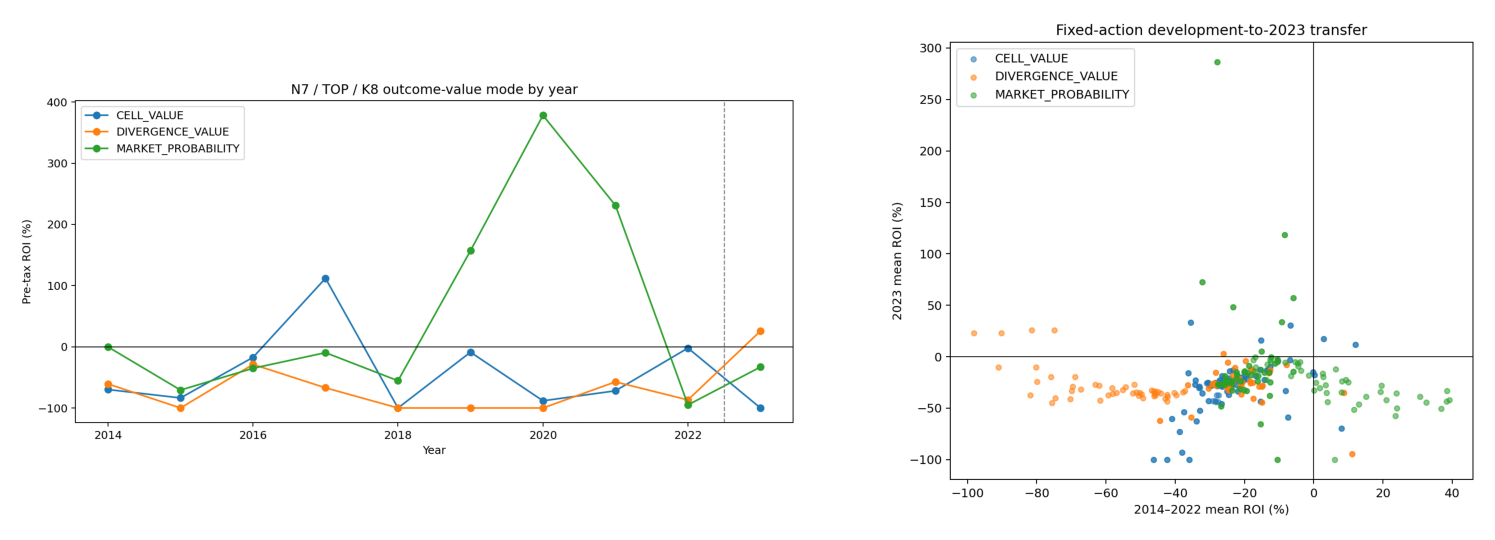

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].imshow(plt.imread(RESULTS / 'outcome_surface_n7_top_k8_yearly.png'))
axes[0].axis('off')
axes[1].imshow(plt.imread(RESULTS / 'outcome_surface_dev_holdout_transfer.png'))
axes[1].axis('off')
plt.tight_layout()
outcome_receipt

The outcome-value dimension is real but nonstationary. The
development winner `MARKET_PROBABILITY / N7 / TOP / K8` moves from +38.54% in
2014–2022 to −33.06% in 2023. `DIVERGENCE_VALUE` moves in the opposite direction
but its positive 2023 result is concentrated in one positive issue. Across all
432 fixed actions, development-to-2023 rank Spearman is only 0.305. Therefore
value mode belongs in the learned action vector, but a fixed historical winner
is not an acceptable baseline replacement.

## Subset-level alias and nuisance confirmation

In [12]:
mode_pivot = outcome_joint.pivot_table(
    index=['issue','n','proposal_family','generator','requested_k'],
    columns='outcome_weight_mode', values='realized_roi_pct'
).dropna()
{
    'CELL_equals_MARKET_fraction': (
        mode_pivot.CELL_VALUE == mode_pivot.MARKET_PROBABILITY
    ).mean(),
    'maximum_absolute_difference': (
        mode_pivot.CELL_VALUE - mode_pivot.MARKET_PROBABILITY
    ).abs().max(),
}

{'CELL_equals_MARKET_fraction': np.float64(1.0),
 'maximum_absolute_difference': np.float64(0.0)}

In [13]:
pd.concat([
    div_n8.assign(confirmation='N8_SHAPE_K16_8SUBSET_5SEED'),
    div_n9.assign(confirmation='N9_DIV_K64_8SUBSET_5SEED'),
], ignore_index=True)[[
    'confirmation','outcome_weight_mode','mean_roi_pct',
    'ex_largest_roi_pct','mean_lift_to_cell_pct',
    'development_roi_pct','holdout_roi_pct','positive_years'
]]

,confirmation,outcome_weight_mode,mean_roi_pct,ex_largest_roi_pct,mean_lift_to_cell_pct,development_roi_pct,holdout_roi_pct,positive_years
0,N8_SHAPE_K16_8SUBSET_5SEED,CELL_VALUE,-2.045029,-14.026067,0.000000,-4.904629,28.493340,5
1,N8_SHAPE_K16_8SUBSET_5SEED,CELL_VALUE,-2.045029,-14.026067,0.000000,-4.904629,28.493340,5
2,N8_SHAPE_K16_8SUBSET_5SEED,DIVERGENCE_VALUE,-12.659174,-18.056459,-10.614145,-17.410525,38.081665,3
3,N8_SHAPE_K16_8SUBSET_5SEED,DIVERGENCE_VALUE,-12.659174,-18.056459,-10.614145,-17.410525,38.081665,3
4,N9_DIV_K64_8SUBSET_5SEED,DIVERGENCE_VALUE,5.266650,-13.406811,33.356255,7.554483,-19.165686,4
5,N9_DIV_K64_8SUBSET_5SEED,DIVERGENCE_VALUE,5.266650,-13.406811,33.356255,7.554483,-19.165686,4
6,N9_DIV_K64_8SUBSET_5SEED,CELL_VALUE,-28.089605,-32.658436,0.000000,-34.038782,35.443115,1
7,N9_DIV_K64_8SUBSET_5SEED,CELL_VALUE,-28.089605,-32.658436,0.000000,-34.038782,35.443115,1


CELL and MARKET are an algebraic alias after fixing the match
subset: predicted SP is a match-level scalar common to all three outcomes, so
it cannot change complete-ticket ordering. DIVERGENCE genuinely changes the
order, but the N8 apparent Edge collapses under 8-subset × 5-seed integration.
N9/K64 retains +5.27% descriptively, yet becomes −13.41% ex-largest and is
negative in 2023. Neither row is a frozen candidate.

## Can issue Data learn the divergence-mode switch?

In [14]:
mode_metrics[[
    'policy','mean_roi_pct','mean_lift_to_cell_pct','ex_largest_roi_pct',
    'bootstrap_lift_low_pct','bootstrap_lift_high_pct',
    'positive_lift_years','divergence_fraction','ending_capital_cny',
    'max_drawdown_fraction'
]]

,policy,mean_roi_pct,mean_lift_to_cell_pct,ex_largest_roi_pct,bootstrap_lift_low_pct,bootstrap_lift_high_pct,positive_lift_years,divergence_fraction,ending_capital_cny,max_drawdown_fraction
0,DIVERGENCE_FIXED,0.014749,31.502992,-8.231520,-4.483626,68.195064,3,1.000000,100004.822764,0.048608
1,PRIOR,0.014749,31.502992,-8.231520,-5.997834,68.830035,3,1.000000,100004.822764,0.048608
2,HGB,-17.935025,13.553218,-26.236354,-19.377988,48.396087,2,0.602446,94135.246782,0.089739
3,MLP,-19.881065,11.607178,-24.671642,-19.970643,41.064675,3,0.743119,93498.891606,0.072821
4,RIDGE,-21.591283,9.896960,-26.387106,-20.969781,39.884366,3,0.822630,92939.650338,0.089589
5,CELL_FIXED,-31.488243,0.000000,-37.272597,0.000000,0.000000,0,0.000000,89703.344458,0.133685
6,HGB_Q10,-35.887856,-4.399613,-41.648437,-22.457049,11.381430,2,0.094801,88264.670987,0.125461


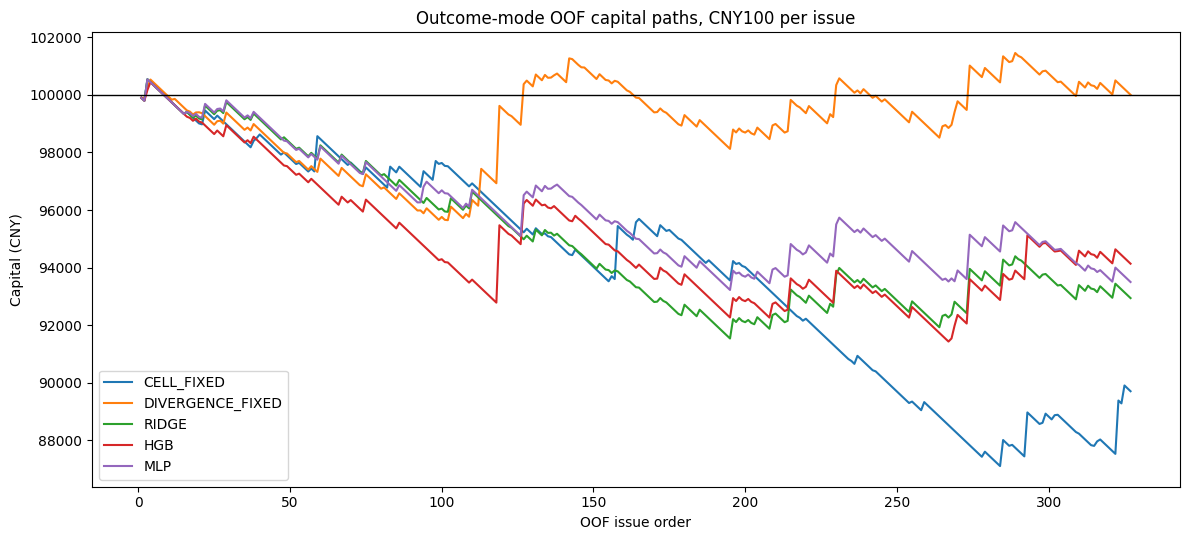

In [15]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for policy in ['CELL_FIXED','DIVERGENCE_FIXED','RIDGE','HGB','MLP']:
    group = mode_selected.loc[mode_selected.policy.eq(policy)].sort_values(
        ['issue_year','issue']
    )
    capital = 100_000 + group.realized_roi_pct.cumsum()
    ax.plot(range(1, len(group)+1), capital, label=policy)
ax.axhline(100_000, color='black', linewidth=1)
ax.set(
    xlabel='OOF issue order', ylabel='Capital (CNY)',
    title='Outcome-mode OOF capital paths, CNY100 per issue'
)
ax.legend(); plt.tight_layout()

Fixed divergence is nearly flat in 2018–2023, but it is a
post-selected development hypothesis. Every Data-conditioned switcher performs
worse. The current 18 aggregate issue features do not explain *when* divergence
ranking works. The next iteration must construct M×3 divergence-shape features
before restoring outcome mode to the complete joint policy.

## Decision rule

This is an exploratory interaction screen, not a promotion gate. A positive
historical cell is only a hypothesis. It must survive nuisance-seed averaging,
denser subset replication, chronological model selection, ex-largest and
issue-block bootstrap checks. The next learned policy must use richer pre-event
matrix features and abstain to the frozen baseline when the lower advantage
bound is not separated from uncertainty. Current aggregate issue-state features
do not support dynamic parameter selection.